# Exercice 3 — Remplacer la Q-table par un cerveau neuronal (DQN)

Sur **CartPole-v1**, l'état est continu (4 réels) : impossible de lister toutes les lignes d'une Q-table.
On **approxime** la fonction $Q(s, a)$ par un réseau de neurones : c'est le **Deep Q-Network**.

Deux implémentations :
1. **Manuelle avec PyTorch** — réseau, *Experience Replay*, *Target Network* et boucle d'entraînement commentée.
2. **Stable-Baselines3** — la même idée en quelques lignes, comme en production.

| Concept | Rôle |
|---|---|
| Policy network $Q_\theta$ | Prédit les Q-values ; c'est lui qu'on entraîne |
| Target network $Q_{\theta^-}$ | Copie figée de $Q_\theta$, mise à jour périodiquement → cible stable |
| Replay buffer | Mémoire de transitions, échantillonnée au hasard → casse la corrélation temporelle |

In [1]:
import random
from collections import deque

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


## Étape 1 — Les classes `DQN` et `ReplayBuffer`

- `DQN` : perceptron multicouche `état (4) → 128 → 128 → Q-values (2)` avec activations ReLU.
- `ReplayBuffer` : une `deque(maxlen=...)` (les plus anciennes transitions sont oubliées automatiquement),
  `push` ajoute une transition, `sample` tire un batch aléatoire avec `random.sample`.

In [2]:
class DQN(nn.Module):
    # Approximateur de Q(s, ·) : une sortie par action.

    def __init__(self, n_observations: int, n_actions: int, hidden: int = 128):
        super().__init__()
        self.layer1 = nn.Linear(n_observations, hidden)
        self.layer2 = nn.Linear(hidden, hidden)
        self.layer3 = nn.Linear(hidden, n_actions)

    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        return self.layer3(x)       # pas d'activation : les Q-values sont des réels quelconques


class ReplayBuffer:
    # Mémoire d'expériences (state, action, reward, next_state, done) de capacité fixe.

    def __init__(self, capacity: int):
        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

In [3]:
env = gym.make("CartPole-v1")
env.action_space.seed(SEED)   # exploration reproductible
n_observations = env.observation_space.shape[0]
n_actions = env.action_space.n

demo_net = DQN(n_observations, n_actions)
print(demo_net)
print("Paramètres entraînables :", sum(p.numel() for p in demo_net.parameters()))

# Test rapide : Q-values pour un état, et le buffer
state, _ = env.reset(seed=SEED)
print("Q(s, ·) =", demo_net(torch.FloatTensor(state)).detach().numpy())
buf = ReplayBuffer(capacity=5)
for i in range(7):
    buf.push(state, i % 2, 1.0, state, False)
print("Taille du buffer (capacité 5, 7 push) :", len(buf), "| échantillon de 2 :", [t[1] for t in buf.sample(2)])

DQN(
  (layer1): Linear(in_features=4, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=2, bias=True)
)
Paramètres entraînables : 17410
Q(s, ·) = [ 0.02073811 -0.01284853]
Taille du buffer (capacité 5, 7 push) : 5 | échantillon de 2 : [0, 0]


## Étape 2 — Boucle d'entraînement du DQN (code « mentor » analysé)

Les points clés sont repérés dans `optimize_model()` :

1. **Sélection d'action** (`select_action`) : epsilon-greedy ; en exploitation, `policy_net(state).argmax()`.
2. **Q-values prédites** : `policy_net(states).gather(1, actions)` — `gather` sélectionne, pour chaque ligne,
   la Q-value de l'action **réellement jouée** (d'où `actions.unsqueeze(1)` : forme `(batch, 1)`).
3. **Q cible** avec le **target network** : `target_net(next_states).max(1)[0]` → meilleure Q-value de l'état
   suivant ; `max(1)` renvoie `(valeurs, indices)`, on garde `[0]`. Multiplié par `(1 - done)` : pas de futur après un état terminal.
   Calcul sous `torch.no_grad()` : on ne rétropropage pas dans la cible.
4. **Perte** : MSE entre Q prédite et cible $r + \gamma \max_{a'} Q_{\theta^-}(s', a')$.
5. **Optimisation** : `zero_grad` → `backward` → *gradient clipping* → `step`.
6. **Mise à jour du target network** : `target_net.load_state_dict(policy_net.state_dict())` tous les `TARGET_UPDATE` épisodes.

Remarque : `done` = `terminated` uniquement. Une troncature (500 pas atteints) n'est **pas** un vrai état terminal,
on continue donc à « bootstrapper » la valeur future.

In [4]:
# Hyperparamètres
N_EPISODES     = 400
BATCH_SIZE     = 64
GAMMA          = 0.99
LR             = 1e-3
BUFFER_SIZE    = 10_000
EPS_START, EPS_END, EPS_DECAY = 1.0, 0.01, 0.98   # décroissance multiplicative par épisode
TARGET_UPDATE  = 10                                # en épisodes

policy_net = DQN(n_observations, n_actions)
target_net = DQN(n_observations, n_actions)
target_net.load_state_dict(policy_net.state_dict())   # au départ, cible = copie exacte
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=LR)
memory = ReplayBuffer(BUFFER_SIZE)


def select_action(state, epsilon):
    # (1) Sélection d'action epsilon-greedy
    if random.random() < epsilon:
        return env.action_space.sample()
    with torch.no_grad():
        q_values = policy_net(torch.FloatTensor(state).unsqueeze(0))   # (1, n_actions)
        return int(q_values.argmax(1).item())


def optimize_model():
    if len(memory) < BATCH_SIZE:
        return None
    transitions = memory.sample(BATCH_SIZE)
    states, actions, rewards, next_states, dones = zip(*transitions)

    # Conversion en tenseurs (FloatTensor pour les réels, LongTensor pour les indices d'action)
    states      = torch.FloatTensor(np.array(states))           # (B, 4)
    actions     = torch.LongTensor(actions).unsqueeze(1)        # (B, 1)
    rewards     = torch.FloatTensor(rewards)                    # (B,)
    next_states = torch.FloatTensor(np.array(next_states))      # (B, 4)
    dones       = torch.FloatTensor(dones)                      # (B,)

    # (2) Q(s, a) prédit par le policy_net pour les actions effectivement jouées
    q_values = policy_net(states).gather(1, actions).squeeze(1)        # (B,)

    # (3) Cible : r + γ · max_a' Q_target(s', a')  — le target_net estime le futur
    with torch.no_grad():
        next_q_values = target_net(next_states).max(1)[0]              # (B,)
        target_q_values = rewards + GAMMA * next_q_values * (1 - dones)

    # (4) Perte entre prédiction et cible
    loss = F.mse_loss(q_values, target_q_values)

    # (5) Étape d'optimisation
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(policy_net.parameters(), 10)
    optimizer.step()
    return loss.item()


episode_rewards = []
epsilon = EPS_START

for episode in range(N_EPISODES):
    state, _ = env.reset(seed=SEED + episode)
    total_reward, done = 0.0, False

    while not done:
        action = select_action(state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        memory.push(state, action, reward, next_state, float(terminated))
        optimize_model()
        state = next_state
        total_reward += reward
        done = terminated or truncated

    epsilon = max(EPS_END, epsilon * EPS_DECAY)

    # (6) Mise à jour périodique du target network : copie des poids du policy_net
    if episode % TARGET_UPDATE == 0:
        target_net.load_state_dict(policy_net.state_dict())

    episode_rewards.append(total_reward)
    if (episode + 1) % 50 == 0:
        print(f"Épisode {episode + 1:4d} | ε = {epsilon:.3f} | "
              f"récompense moyenne (50 derniers) = {np.mean(episode_rewards[-50:]):6.1f}")

env.close()

Épisode   50 | ε = 0.364 | récompense moyenne (50 derniers) =   21.3


Épisode  100 | ε = 0.133 | récompense moyenne (50 derniers) =  132.8


Épisode  150 | ε = 0.048 | récompense moyenne (50 derniers) =  195.2


Épisode  200 | ε = 0.018 | récompense moyenne (50 derniers) =  159.2


Épisode  250 | ε = 0.010 | récompense moyenne (50 derniers) =  189.6


Épisode  300 | ε = 0.010 | récompense moyenne (50 derniers) =  184.3


Épisode  350 | ε = 0.010 | récompense moyenne (50 derniers) =  213.6


Épisode  400 | ε = 0.010 | récompense moyenne (50 derniers) =  287.0


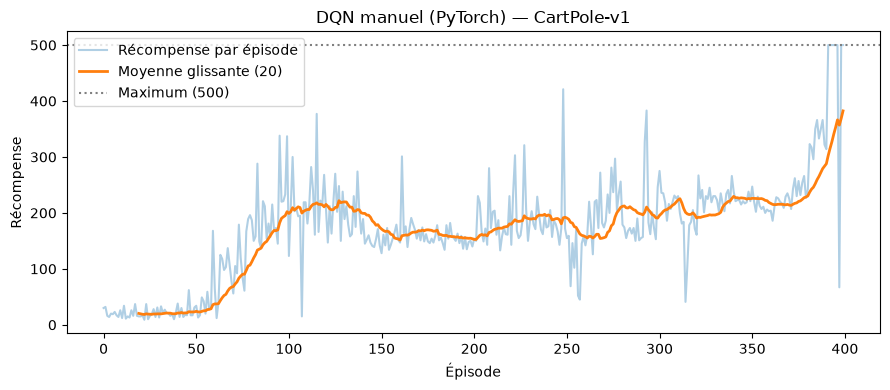

In [5]:
window = 20
plt.figure(figsize=(9, 4))
plt.plot(episode_rewards, alpha=0.35, label="Récompense par épisode")
plt.plot(range(window - 1, len(episode_rewards)),
         np.convolve(episode_rewards, np.ones(window) / window, mode="valid"),
         lw=2, label=f"Moyenne glissante ({window})")
plt.axhline(500, color="gray", ls=":", label="Maximum (500)")
plt.xlabel("Épisode"); plt.ylabel("Récompense"); plt.title("DQN manuel (PyTorch) — CartPole-v1")
plt.legend(); plt.tight_layout(); plt.show()

**Lecture** : la récompense moyenne passe d'environ 25 à plusieurs centaines, mais la courbe est **bruitée et non monotone**
(et varie d'un run à l'autre) : c'est l'instabilité typique du DQN « vanilla » ; le DQN « vanilla » est connu pour être instable
(oublis catastrophiques, sur-estimation des Q-values). Les bibliothèques comme SB3 intègrent des réglages éprouvés.

Évaluation rapide de la politique gloutonne apprise (ε = 0) :

In [6]:
eval_env = gym.make("CartPole-v1")
scores = []
for i in range(20):
    s, _ = eval_env.reset(seed=1_000 + i)
    done, score = False, 0.0
    while not done:
        s, r, term, trunc, _ = eval_env.step(select_action(s, epsilon=0.0))
        score += r; done = term or trunc
    scores.append(score)
eval_env.close()
print(f"DQN manuel — récompense moyenne sur 20 épisodes : {np.mean(scores):.1f} ± {np.std(scores):.1f}")

DQN manuel — récompense moyenne sur 20 épisodes : 256.7 ± 13.2


## Étape 3 — Le même agent avec Stable-Baselines3

Toute la mécanique précédente (réseau, replay buffer, target network, epsilon-greedy) est encapsulée dans `DQN('MlpPolicy', env)`.

⚠️ `total_timesteps` = nombre d'**interactions** avec l'environnement (pas d'épisodes).

### 3.a — Paramètres par défaut (25 000 pas)

In [7]:
from stable_baselines3 import DQN as SB3_DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

env = Monitor(gym.make("CartPole-v1"))   # Monitor : statistiques d'épisodes fiables pour evaluate_policy
model = SB3_DQN("MlpPolicy", env, verbose=0, seed=SEED, tensorboard_log="../logs/exercice_3/")
model.learn(total_timesteps=25_000, tb_log_name="dqn_default")

mean_reward, std_reward = evaluate_policy(model, env, n_eval_episodes=100)
print(f"SB3 DQN (défaut, 25k pas) : {mean_reward:.1f} ± {std_reward:.1f}")

SB3 DQN (défaut, 25k pas) : 22.5 ± 4.0


### 3.b — Hyperparamètres ajustés

Les valeurs par défaut de SB3 sont pensées pour Atari (target mis à jour tous les 10 000 pas, exploration
courte…) : sur un budget de 25 000 pas, c'est trop lent. On reprend les réglages publiés par **RL Zoo**
pour CartPole — un avant-goût de l'optimisation d'hyperparamètres de la mission.

In [8]:
tuned_model = SB3_DQN(
    "MlpPolicy", env,
    learning_rate=2.3e-3,
    batch_size=64,
    buffer_size=100_000,
    learning_starts=1_000,
    gamma=0.99,
    target_update_interval=10,
    train_freq=256,
    gradient_steps=128,
    exploration_fraction=0.16,
    exploration_final_eps=0.04,
    policy_kwargs=dict(net_arch=[256, 256]),
    verbose=0, seed=SEED, tensorboard_log="../logs/exercice_3/",
)
tuned_model.learn(total_timesteps=50_000, tb_log_name="dqn_tuned")

tuned_mean, tuned_std = evaluate_policy(tuned_model, env, n_eval_episodes=100)
print(f"SB3 DQN (ajusté, 50k pas) : {tuned_mean:.1f} ± {tuned_std:.1f}")

SB3 DQN (ajusté, 50k pas) : 500.0 ± 0.0


### Sauvegarde (.zip) et rechargement du meilleur modèle

In [9]:
best = tuned_model if tuned_mean >= mean_reward else model
best.save("../models/dqn_cartpole")          # -> models/dqn_cartpole.zip

reloaded = SB3_DQN.load("../models/dqn_cartpole", env=env)
m, s = evaluate_policy(reloaded, env, n_eval_episodes=100)
print(f"Modèle rechargé depuis models/dqn_cartpole.zip : {m:.1f} ± {s:.1f}")
env.close()

Modèle rechargé depuis models/dqn_cartpole.zip : 500.0 ± 0.0


## Aperçu visuel

**Animation de l'agent SB3 entraîné** : il tient les 500 pas (une image sur trois est conservée).

Agent entraîné : 500 pas


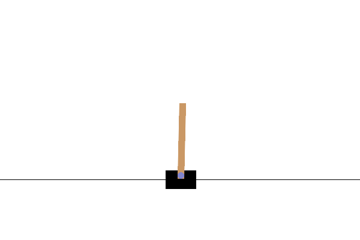

In [10]:
from rl_viz import rollout, save_gif, trajectories_3d, surface_3d

env_vis = gym.make("CartPole-v1", render_mode="rgb_array")
trained_policy = lambda obs: int(best.predict(obs, deterministic=True)[0])

total, trained_states, frames = rollout(env_vis, trained_policy, seed=7, render=True)
print(f"Agent entraîné : {total:.0f} pas")
save_gif(frames, "ex3_cartpole_dqn.gif", fps=30, every=3)

**Trajectoires 3D : aléatoire vs entraîné.** L'agent aléatoire diverge en quelques pas ; l'agent DQN reste
confiné près de θ = 0 en oscillant autour de l'équilibre pendant les 500 pas.

In [11]:
random_policy = lambda obs: env_vis.action_space.sample()
runs = [("aléatoire " + str(i + 1), rollout(env_vis, random_policy, seed=i)[1]) for i in range(3)]
runs += [("DQN entraîné", trained_states)]
env_vis.close()
trajectories_3d(runs, "ex3_trajectoires_3d", "CartPole — trajectoires : aléatoire vs DQN",
                labels=("Position x", "Angle θ (rad)", "Vitesse angulaire θ̇"))

**Ce que le réseau a appris : paysage des Q-values en 3D.** On fixe x = 0 et ẋ = 0 et on balaie l'angle θ
et la vitesse angulaire θ̇. Hauteur = $\max_a Q(s, a)$, couleur = action choisie (bleu = gauche, orange = droite).
Au centre, la frontière de décision est une diagonale : l'agent pousse du côté où le bâton tombe
(à droite quand θ + k·θ̇ > 0). Dans les coins extrêmes, états jamais visités pendant l'entraînement,
les décisions deviennent incohérentes : le réseau n'y a rien appris.

In [12]:
thetas = np.linspace(-0.2, 0.2, 61)
theta_dots = np.linspace(-1.5, 1.5, 61)
T, TD = np.meshgrid(thetas, theta_dots)
grid = np.stack([np.zeros_like(T), np.zeros_like(T), T, TD], axis=-1).reshape(-1, 4)

with torch.no_grad():
    q = best.q_net(torch.as_tensor(grid, dtype=torch.float32, device=best.device)).cpu().numpy()

surface_3d(q.max(1).reshape(T.shape), "ex3_q_values_3d",
           "DQN SB3 — max Q(s, a) selon θ et θ̇ (couleur : action choisie)",
           x=thetas, y=theta_dots, labels=("Angle θ (rad)", "Vitesse angulaire θ̇", "max Q"),
           color=q.argmax(1).reshape(T.shape).astype(float),
           colorscale=[[0, "#4C72B0"], [1, "#DD8452"]], colorbar_title="action")

## Bilan : DQN manuel vs Stable-Baselines3

| | DQN manuel (PyTorch) | DQN Stable-Baselines3 |
|---|---|---|
| Lignes de code | ~80 | ~5 |
| Unité de budget | épisodes | `total_timesteps` (interactions) |
| Contrôle / pédagogie | Total : on voit chaque tenseur | Boîte noire configurable |
| Outils fournis | à coder | évaluation, sauvegarde `.zip`, TensorBoard, callbacks |
| Résultat obtenu | ~257 sur 20 épisodes, courbe instable | défaut 25k pas : 22,5 · ajusté 50k pas : **500 ± 0** (100 épisodes) |
| Sensibilité aux hyperparamètres | forte | forte aussi (cf. défaut vs ajusté) |

**À retenir** : le DQN remplace la Q-table par un réseau ; le *replay buffer* et le *target network* sont
ce qui rend l'apprentissage stable. Les hyperparamètres comptent autant que l'algorithme — ce sera le cœur
de la mission LunarLander.

Les courbes d'entraînement SB3 sont visibles dans TensorBoard (`logs/exercice_3`).